<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/05_Classification/notebooks/03_Decision_Tree_Introduction_and_Mathematics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

from sklearn.model_selection import train_test_split

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
#Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Feature names:", iris.feature_names)
print("Target names:", iris.target_names)

Feature shape: (150, 4)
Target shape: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [3]:
#Create a DataFrame
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["Target"] = y

df["Flower"] = df["Target"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,Flower
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [4]:
#Explore the dataset
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["Flower"].value_counts())

Dataset shape: (150, 6)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
Flower               0
dtype: int64

Class distribution:
Flower
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [6]:
#Create the Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

In [7]:
#Train the model
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [8]:
#Make predictions
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [9]:
#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9333333333333333


[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


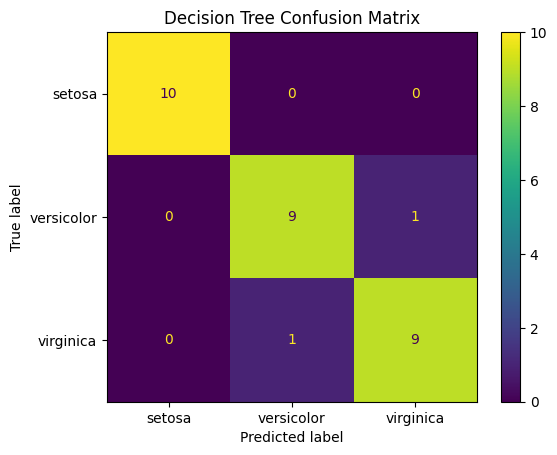

In [10]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [11]:
#Classification Report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



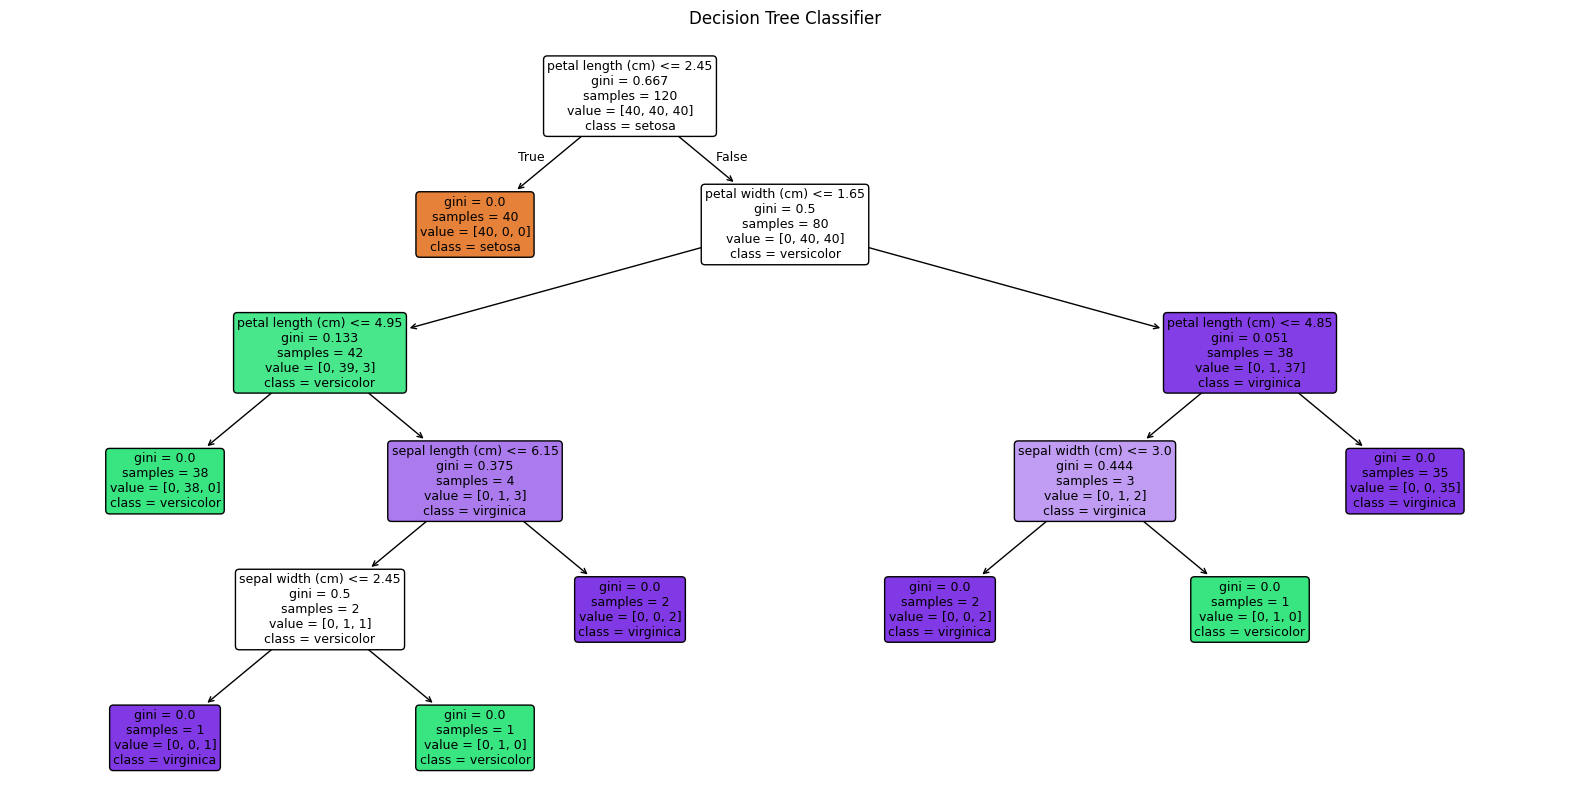

In [12]:
#Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classifier")

plt.show()

In [13]:
#Extract the tree rules as text
tree_rules = export_text(
    model,
    feature_names=iris.feature_names
)

print(tree_rules)

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- sepal length (cm) <= 6.15
|   |   |   |   |--- sepal width (cm) <= 2.45
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- sepal width (cm) >  2.45
|   |   |   |   |   |--- class: 1
|   |   |   |--- sepal length (cm) >  6.15
|   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.00
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.00
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2



In [14]:
#Experiment with Entropy
entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model.fit(X_train, y_train)

entropy_predictions = entropy_model.predict(X_test)

print(
    "Entropy Accuracy:",
    accuracy_score(y_test, entropy_predictions)
)

print(
    "Gini Accuracy:",
    accuracy_score(y_test, y_pred)
)

Entropy Accuracy: 0.9333333333333333
Gini Accuracy: 0.9333333333333333


In [15]:
#Compare both models
comparison = pd.DataFrame({
    "Criterion": ["Gini", "Entropy"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, entropy_predictions)
    ],
    "Tree Depth": [
        model.get_depth(),
        entropy_model.get_depth()
    ],
    "Leaf Nodes": [
        model.get_n_leaves(),
        entropy_model.get_n_leaves()
    ]
})

comparison

,Criterion,Accuracy,Tree Depth,Leaf Nodes
0,Gini,0.933333,5,8
1,Entropy,0.933333,5,8
